# AnyCam — 03 · Step 5: baseline training (normal model, all 204 bands)

Trains a ResNet18 (ImageNet weights, first layer widened to 204 bands) on HyperLeaf2024 and tests it
on the official test plots. Expected: cultivar accuracy close to the HyperLeaf paper (~0.89).

**Before running (right panel):**
1. **Add Input** → Competitions → **HyperLeaf2024**
2. **Settings → Accelerator → GPU T4 x2** (or P100)
3. **Settings → Internet → On**
4. Optional: Add-ons → Secrets → `GITHUB_WRITE_TOKEN` (On) to upload results to GitHub automatically

Then **Run All** (about 10-20 minutes).

In [1]:
import os, subprocess, glob, json, shutil, pathlib
REPO = 'https://github.com/ShahnawazQ007/one-model-many-camera.git'
if not os.path.exists('/kaggle/working/anycam'):
    subprocess.run(['git', 'clone', '-q', '--depth', '1', REPO, '/kaggle/working/anycam'], check=True)
else:
    subprocess.run(['git', '-C', '/kaggle/working/anycam', 'pull', '-q'], check=True)
os.chdir('/kaggle/working/anycam')
!pip -q install timm tifffile imagecodecs
import torch; print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - turn on the GPU accelerator!')

GPU: Tesla T4


In [2]:
# find the HyperLeaf data folder (searches everything under /kaggle/input)
hits = [os.path.dirname(f) for f in glob.glob('/kaggle/input/**/train.csv', recursive=True)
        if os.path.isdir(os.path.join(os.path.dirname(f), 'images'))]
if not hits:
    print('Inputs attached to this notebook:')
    for d in glob.glob('/kaggle/input/**/', recursive=True)[:30]: print('  ', d)
    raise SystemExit('HyperLeaf not found: in the right panel, Add Input -> search hyperleaf -> the one with the trophy icon (+)')
DATA = hits[0]
print('data:', DATA, '| images:', len(glob.glob(f'{DATA}/images/*.tiff')))

data: /kaggle/input/competitions/HyperLeaf2024 | images: 2410


In [3]:
# Step 5a: official competition split (train plots vs test plots)
!python experiments/train_baseline.py --data {DATA} --split official --epochs 40 --workers 4 --out runs/baseline_official

device cuda | train 1410 val 180 test 820 leaves

model.safetensors: downloading bytes: ██▋                   | 5.63MB            
model.safetensors: downloading bytes: ████████████████████▍ | 43.4MB, 3.10MB/s  
model.safetensors: downloading bytes: ██████████████████████| 44.0MB, 4.21MB/s  
model.safetensors: reconstructing file: 100%|██████| 46.8MB / 46.8MB, 4.55MB/s  
model resnet18: 11.81M parameters
epoch  0 train 2.243 val 2.282 (40s)
epoch  1 train 1.791 val 1.914 (69s)
epoch  2 train 1.469 val 1.885 (97s)
epoch  3 train 1.186 val 1.626 (125s)
epoch  4 train 0.998 val 1.493 (153s)
epoch  5 train 0.809 val 1.512 (181s)
epoch  6 train 0.739 val 1.502 (209s)
epoch  7 train 0.639 val 1.277 (237s)
epoch  8 train 0.555 val 1.354 (264s)
epoch  9 train 0.504 val 1.309 (292s)
epoch 10 train 0.477 val 1.441 (320s)
epoch 11 train 0.413 val 1.413 (348s)
epoch 12 train 0.404 val 1.555 (375s)
epoch 13 train 0.370 val 1.698 (404s)
epoch 14 train 0.365 val 1.589 (431s)
epoch 15 train 0.328 val 

In [4]:
# Step 5b (optional, ~10-15 min more): first fold of the plot-grouped cross-validation
!python experiments/train_baseline.py --data {DATA} --split cv --seed 0 --fold 0 --epochs 40 --workers 4 --out runs/baseline_cv_s0_f0

device cuda | train 1850 val 190 test 370 leaves
model resnet18: 11.81M parameters
epoch  0 train 2.122 val 2.261 (41s)
epoch  1 train 1.666 val 2.207 (77s)
epoch  2 train 1.288 val 1.692 (113s)
epoch  3 train 1.022 val 1.478 (149s)
epoch  4 train 0.872 val 1.649 (184s)
epoch  5 train 0.744 val 1.408 (219s)
epoch  6 train 0.637 val 1.344 (254s)
epoch  7 train 0.559 val 1.205 (289s)
epoch  8 train 0.515 val 1.286 (325s)
epoch  9 train 0.463 val 1.285 (360s)
epoch 10 train 0.426 val 1.329 (395s)
epoch 11 train 0.410 val 1.295 (430s)
epoch 12 train 0.370 val 1.126 (465s)
epoch 13 train 0.330 val 1.140 (500s)
epoch 14 train 0.304 val 1.311 (535s)
epoch 15 train 0.284 val 1.320 (570s)
epoch 16 train 0.296 val 1.332 (605s)
epoch 17 train 0.269 val 1.072 (640s)
epoch 18 train 0.249 val 1.175 (675s)
epoch 19 train 0.233 val 1.523 (711s)
epoch 20 train 0.208 val 1.259 (746s)
epoch 21 train 0.198 val 1.375 (781s)
epoch 22 train 0.197 val 1.324 (816s)
epoch 23 train 0.190 val 1.313 (851s)
epoch 2

saved runs/baseline_cv_s0_f0/figures.png
saved runs/baseline_official/figures.png
runs/baseline_cv_s0_f0/figures.png


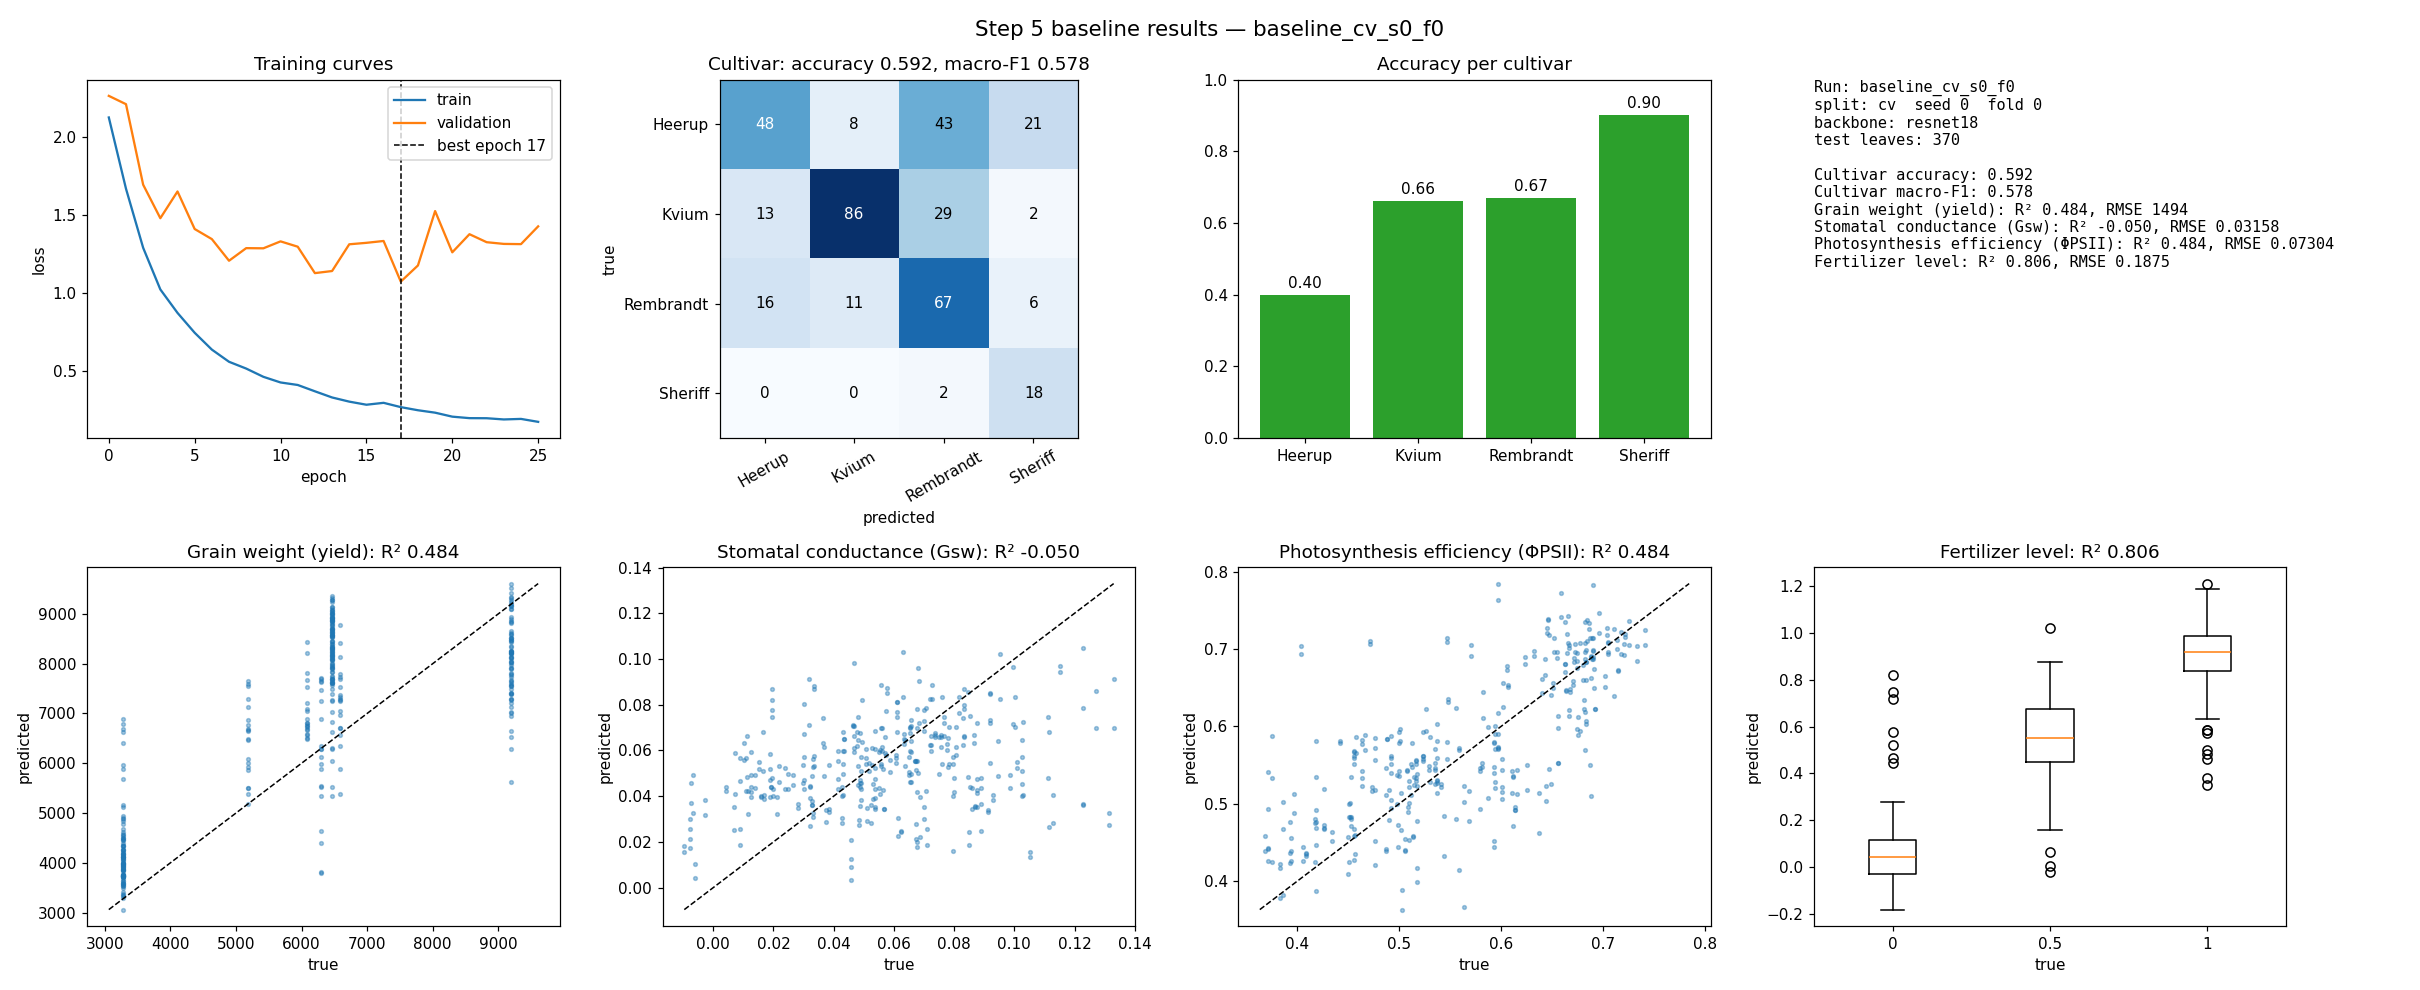

runs/baseline_official/figures.png


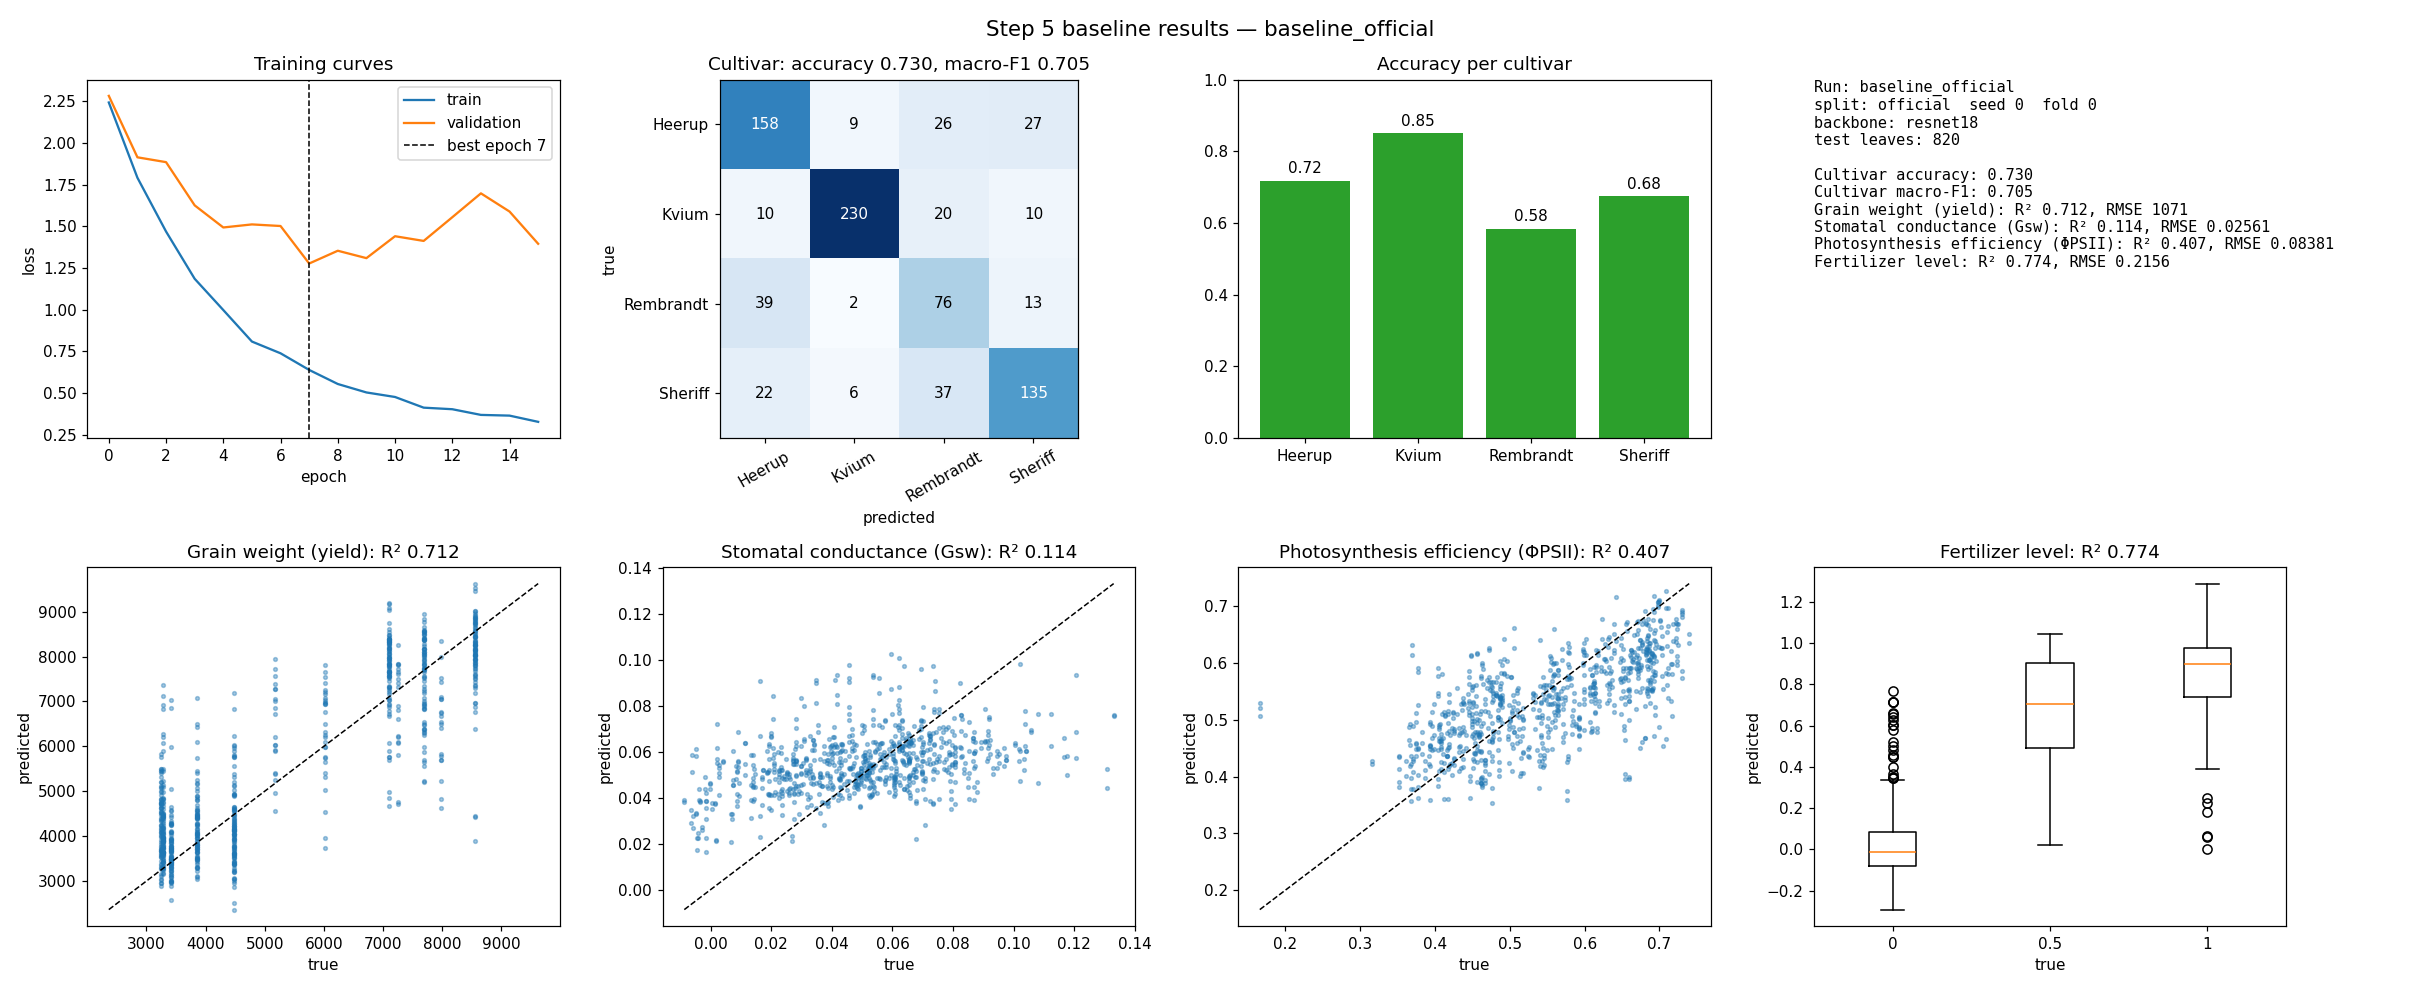

In [5]:
# figures: training curves, confusion matrix, per-cultivar accuracy, predicted vs true for each trait
!python scripts/plot_run.py runs/*
from IPython.display import Image, display
for f in sorted(glob.glob('runs/*/figures.png')):
    print(f); display(Image(f))


In [6]:
# collect the small result files (no model weights) and upload them to GitHub results/ if the token is set
res = pathlib.Path('/kaggle/working/step05_results'); res.mkdir(exist_ok=True)
for run in glob.glob('runs/*'):
    dst = res / pathlib.Path(run).name; dst.mkdir(exist_ok=True)
    for f in ['metrics.json', 'predictions.csv', 'history.csv', 'config.json', 'band_norm.json', 'figures.png']:
        if os.path.exists(f'{run}/{f}'): shutil.copy(f'{run}/{f}', dst)
    print(pathlib.Path(run).name, json.dumps(json.load(open(f'{run}/metrics.json'))['cultivar']))
subprocess.run(['python', 'scripts/push_results.py', str(res), 'step05_baseline'])

baseline_official {"accuracy": 0.7304878048780488, "macro_f1": 0.7051962498129731}
baseline_cv_s0_f0 {"accuracy": 0.5918918918918918, "macro_f1": 0.5781386421583166}
No GITHUB_WRITE_TOKEN secret: results stay on Kaggle (Output tab). See docs/SETUP_GITHUB_KAGGLE.md, Part 6.


CompletedProcess(args=['python', 'scripts/push_results.py', '/kaggle/working/step05_results', 'step05_baseline'], returncode=0)

## Done
If the last cell says **Uploaded to GitHub**, tell Claude "done". Otherwise download the folder
`/kaggle/working/step05_results` from the Output tab and send it to Claude.